In [1]:
import pandas as pd
import os
from PIL import Image
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("rpc/train.csv")
df

,ImgId,title,description,categories
0,B000HYL1V6,TUNGSTEN SOLDER PICK WITH HANDLE,Solder Pick for picking up molten solder when ...,"Arts, Crafts & Sewing"
1,B00006HXWY,Write Right 98167 Screen Protector for Sony T615C,We all screen. And we all need to protect thos...,Cell Phones & Accessories
2,B000GAWSBS,Casio Mens DBC310-1 Databank 300 Digital Watch...,"Bringing you precision at a glance, the Casio ...","Clothing, Shoes & Jewelry"
3,B000040JOL,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Tools & Home Improvement
4,B00006IB78,Energizer 2 in 1 Light,This twoway light features a bright flashlight...,Health & Personal Care
...,...,...,...,...
46224,B0000AV1J7,"Berkley Trilene XL 1000 - yard Fishing Line, C...",Smooth - casting Berkley Trilene XL Fishing Li...,Sports & Outdoors
46225,B0006MZPLG,Badger Air-Brush Company Basic Spray Gun Set,"An easy to use, top quality spray gun for the ...","Arts, Crafts & Sewing"
46226,B000GBO8SS,Fimo Soft Polymer Clay 2 Ounces-8020-53 Tropic...,Fimo Soft Polymer Clay is easier to use than b...,"Arts, Crafts & Sewing"
46227,B0000VMA16,Wilton Icing Colors 1 Oz: Rose Petal,Icing Colors. This plastic bottle contains 1 o...,Grocery & Gourmet Food


In [3]:
df.categories.value_counts()

categories
Arts, Crafts & Sewing        2225
Beauty                       2202
Sports & Outdoors            2201
Grocery & Gourmet Food       2201
Cell Phones & Accessories    2200
Clothing, Shoes & Jewelry    2200
Tools & Home Improvement     2200
Health & Personal Care       2200
Baby Products                2200
Baby                         2200
Patio, Lawn & Garden         2200
Electronics                  2200
All Electronics              2200
Automotive                   2200
Toys & Games                 2200
All Beauty                   2200
Office Products              2200
Appliances                   2200
Musical Instruments          2200
Industrial & Scientific      2200
Pet Supplies                 2200
Name: count, dtype: int64

In [4]:
df.isna().sum()

ImgId             0
title             1
description    1042
categories        0
dtype: int64

In [5]:
df = df.fillna("")

In [6]:
df.isna().sum()

ImgId          0
title          0
description    0
categories     0
dtype: int64

In [7]:
len(os.listdir("rpc/train/train"))

42000

In [8]:
df["path"] = "rpc/train/train/" + df["ImgId"] + ".jpg"

In [9]:
df

,ImgId,title,description,categories,path
0,B000HYL1V6,TUNGSTEN SOLDER PICK WITH HANDLE,Solder Pick for picking up molten solder when ...,"Arts, Crafts & Sewing",rpc/train/train/B000HYL1V6.jpg
1,B00006HXWY,Write Right 98167 Screen Protector for Sony T615C,We all screen. And we all need to protect thos...,Cell Phones & Accessories,rpc/train/train/B00006HXWY.jpg
2,B000GAWSBS,Casio Mens DBC310-1 Databank 300 Digital Watch...,"Bringing you precision at a glance, the Casio ...","Clothing, Shoes & Jewelry",rpc/train/train/B000GAWSBS.jpg
3,B000040JOL,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Tools & Home Improvement,rpc/train/train/B000040JOL.jpg
4,B00006IB78,Energizer 2 in 1 Light,This twoway light features a bright flashlight...,Health & Personal Care,rpc/train/train/B00006IB78.jpg
...,...,...,...,...,...
46224,B0000AV1J7,"Berkley Trilene XL 1000 - yard Fishing Line, C...",Smooth - casting Berkley Trilene XL Fishing Li...,Sports & Outdoors,rpc/train/train/B0000AV1J7.jpg
46225,B0006MZPLG,Badger Air-Brush Company Basic Spray Gun Set,"An easy to use, top quality spray gun for the ...","Arts, Crafts & Sewing",rpc/train/train/B0006MZPLG.jpg
46226,B000GBO8SS,Fimo Soft Polymer Clay 2 Ounces-8020-53 Tropic...,Fimo Soft Polymer Clay is easier to use than b...,"Arts, Crafts & Sewing",rpc/train/train/B000GBO8SS.jpg
46227,B0000VMA16,Wilton Icing Colors 1 Oz: Rose Petal,Icing Colors. This plastic bottle contains 1 o...,Grocery & Gourmet Food,rpc/train/train/B0000VMA16.jpg


In [10]:
df["photo"]=df["path"].apply(os.path.exists)
df["photo"].value_counts()

photo
True     42000
False     4229
Name: count, dtype: int64

In [11]:
df = df[df["photo"]]
df

,ImgId,title,description,categories,path,photo
0,B000HYL1V6,TUNGSTEN SOLDER PICK WITH HANDLE,Solder Pick for picking up molten solder when ...,"Arts, Crafts & Sewing",rpc/train/train/B000HYL1V6.jpg,True
1,B00006HXWY,Write Right 98167 Screen Protector for Sony T615C,We all screen. And we all need to protect thos...,Cell Phones & Accessories,rpc/train/train/B00006HXWY.jpg,True
2,B000GAWSBS,Casio Mens DBC310-1 Databank 300 Digital Watch...,"Bringing you precision at a glance, the Casio ...","Clothing, Shoes & Jewelry",rpc/train/train/B000GAWSBS.jpg,True
3,B000040JOL,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Tools & Home Improvement,rpc/train/train/B000040JOL.jpg,True
4,B00006IB78,Energizer 2 in 1 Light,This twoway light features a bright flashlight...,Health & Personal Care,rpc/train/train/B00006IB78.jpg,True
...,...,...,...,...,...,...
43269,B009XBOU6W,DVD Family Album #27 (DVD Only no Book) [Healt...,Instruction DVD Short - Medium - Long - Color ...,All Beauty,rpc/train/train/B009XBOU6W.jpg,True
43334,B001RSCRZ0,Kiehls - Pineapple Papaya Facial Scrub - 3.4 oz,Formulated with real pineapple & papaya fruit ...,All Beauty,rpc/train/train/B001RSCRZ0.jpg,True
43349,B0030EVCDW,Youth Serum 50ml/1.7 Oz. Anti-wrinkle with 4% ...,Youth products are one of our top sellers for ...,All Beauty,rpc/train/train/B0030EVCDW.jpg,True
43393,B00BLHIXXC,Women's Long Sleeve Studded Bandage Pencil Dre...,Sexy Lady's Long Sleeve Bodycon DressStyle: Wi...,All Beauty,rpc/train/train/B00BLHIXXC.jpg,True


In [12]:
df = df.drop("photo", axis=1)
df.head()

,ImgId,title,description,categories,path
0,B000HYL1V6,TUNGSTEN SOLDER PICK WITH HANDLE,Solder Pick for picking up molten solder when ...,"Arts, Crafts & Sewing",rpc/train/train/B000HYL1V6.jpg
1,B00006HXWY,Write Right 98167 Screen Protector for Sony T615C,We all screen. And we all need to protect thos...,Cell Phones & Accessories,rpc/train/train/B00006HXWY.jpg
2,B000GAWSBS,Casio Mens DBC310-1 Databank 300 Digital Watch...,"Bringing you precision at a glance, the Casio ...","Clothing, Shoes & Jewelry",rpc/train/train/B000GAWSBS.jpg
3,B000040JOL,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Factory-Reconditioned DEWALT DW260KR Heavy-Dut...,Tools & Home Improvement,rpc/train/train/B000040JOL.jpg
4,B00006IB78,Energizer 2 in 1 Light,This twoway light features a bright flashlight...,Health & Personal Care,rpc/train/train/B00006IB78.jpg


Arts, Crafts & Sewing


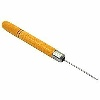

In [13]:
print(df["categories"].iloc[0])
Image.open(df["path"].iloc[0])

Toys & Games


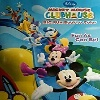

In [14]:
print(df["categories"].iloc[1008])
Image.open(df["path"].iloc[1008])

In [15]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["categories"], random_state=42)
train_df.shape, test_df.shape

((33600, 5), (8400, 5))

In [16]:
train_df.to_csv("train_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)